# Week 3 – Customer Behavior Analysis
**Goal:** analyse customer purchase records to find popular products, buying patterns and customer segments, then turn the results into actionable insights.

**Data:** synthetic purchase records (Oct 2025 – Sep 2026) created by `src/generate_data.py`. It is sample data, not a real retailer.

**Steps:** 1) load and inspect, 2) clean and transform with Pandas, 3) popular products, 4) buying patterns, 5) customer segments (RFM), 6) save results.

In [1]:
import itertools, json, os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 150)
os.makedirs("charts", exist_ok=True)

# Chart styling: validated blue/orange pair, quiet gridlines, ink-coloured text
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlecolor": INK, "axes.titlelocation": "left", "font.size": 10, "text.color": INK2,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"charts/{name}.png", dpi=150); plt.show()

## 1. Load and inspect the raw data

In [2]:
raw = pd.read_csv("data/raw_transactions.csv")
print("Shape:", raw.shape)
display(raw.head(8))
print("\nMissing values per column:"); print(raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())
print("\nCategory spellings:", sorted(raw["category"].unique()))
print("City spellings:", sorted(raw["city"].unique()))
print("Sample of text prices:", raw.loc[raw["unit_price"].astype(str).str.contains("Rs"), "unit_price"].head(3).tolist())

Shape: (1762, 9)


,order_id,customer_id,order_date,product,category,unit_price,quantity,payment_method,city
0,ORD-10001,C0044,2025-10-01,Backpack,Fashion,1499,NaN,Card,Delhi
1,ORD-10002,C0187,2025-10-01,Desk Lamp,Home & Kitchen,899,1.0,UPI,Chennai
2,ORD-10003,C0279,01-Oct-2025,Cushion Set,Home & Kitchen,799,3.0,UPI,Delhi
3,ORD-10004,C0083,02-Oct-2025,Cotton T-Shirt,Fashion,599,3.0,UPI,Mumbai
4,ORD-10005,C0113,02/10/2025,Green Tea Pack,Health & Wellness,349,1.0,Card,Hyderabad
5,ORD-10006,C0123,02-Oct-2025,Power Bank,Electronics,1299,1.0,UPI,Kolkata
6,ORD-10007,C0139,02-Oct-2025,Cushion Set,Home & Kitchen,799,2.0,UPI,Hyderabad
7,ORD-10008,C0180,02-Oct-2025,Backpack,Fashion,1499,1.0,COD,Mumbai



Missing values per column:
order_id           0
customer_id       21
order_date         0
product            0
category           0
unit_price         0
quantity          15
payment_method    25
city               0
dtype: int64

Exact duplicate rows: 30

Category spellings: ['ELECTRONICS', 'Electronics', 'Electronics ', 'FASHION', 'Fashion', 'Fashion ', 'HEALTH & WELLNESS', 'HOME & KITCHEN', 'Health & Wellness', 'Health & Wellness ', 'Home & Kitchen', 'Home & Kitchen ', 'electronics', 'fashion', 'health & wellness', 'home & kitchen']
City spellings: ['Bangalore', 'Bengaluru', 'Bengaluru ', 'Chennai', 'Chennai ', 'Delhi', 'Delhi ', 'Hyderabad', 'Jaipur', 'Jaipur ', 'Kolkata', 'Kolkata ', 'Mumbai', 'Mumbai ', 'Pune', 'Pune ', 'bengaluru', 'chennai', 'delhi', 'hyderabad', 'jaipur', 'kolkata', 'mumbai', 'pune']
Sample of text prices: ['Rs. 599', 'Rs. 2,999', 'Rs. 499']


## 2. Clean and transform
Every fix is logged with the number of rows it touched. Assumptions are stated where a judgement was needed.

In [3]:
log = []
clean = raw.copy()

# 1) exact duplicates
n = clean.duplicated().sum()
clean = clean.drop_duplicates().copy()
log.append(("Exact duplicate rows removed", int(n)))

# 2) order-level fields: recover blanks from other lines of the same order, then handle what is left
for col in ["customer_id", "payment_method"]:
    before = clean[col].isna().sum()
    clean[col] = clean.groupby("order_id")[col].transform("first")
    log.append((f"Blank {col} recovered from the same order's other lines", int(before - clean[col].isna().sum())))
n = clean["customer_id"].isna().sum()
clean = clean.dropna(subset=["customer_id"]).copy()
log.append(("Rows dropped: customer_id still blank (cannot be assigned to a customer)", int(n)))
n = clean["payment_method"].isna().sum()
clean["payment_method"] = clean["payment_method"].fillna("Unknown")
log.append(("Blank payment_method labelled 'Unknown'", int(n)))

# 3) mixed date formats -> real datetimes
non_iso = (~clean["order_date"].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$")).sum()
def parse_date(s):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"):
        try: return pd.to_datetime(s, format=fmt)
        except (ValueError, TypeError): pass
    return pd.NaT
clean["order_date"] = clean["order_date"].map(parse_date)
log.append(("Dates in non-ISO formats converted to datetime", int(non_iso)))

# 4) prices stored as text ("Rs. 1,999") -> numbers
txt = clean["unit_price"].astype(str).str.contains("Rs").sum()
clean["unit_price"] = pd.to_numeric(clean["unit_price"].astype(str).str.replace(r"[^0-9.]", "", regex=True))
log.append(("Text prices converted to numbers", int(txt)))

# 5) inconsistent text
before = clean["category"].copy()
clean["category"] = clean["category"].str.strip().str.title()
log.append(("Category text standardised (case/spaces)", int((before != clean["category"]).sum())))
before = clean["city"].copy()
clean["city"] = clean["city"].str.strip().str.title().replace({"Bangalore": "Bengaluru"})
log.append(("City text standardised (case/spaces, Bangalore -> Bengaluru)", int((before != clean["city"]).sum())))

# 6) quantity: blanks -> most common value; negatives -> absolute value (assumed entry error)
mode_qty = int(clean["quantity"].mode()[0])
n = clean["quantity"].isna().sum()
clean["quantity"] = clean["quantity"].fillna(mode_qty)
log.append((f"Blank quantity filled with the most common value ({mode_qty})", int(n)))
n = (clean["quantity"] < 0).sum()
clean["quantity"] = clean["quantity"].abs().astype(int)
log.append(("Negative quantity converted to positive (assumed sign error)", int(n)))

# 7) derived columns
clean["revenue"] = clean["quantity"] * clean["unit_price"]
clean["month"] = clean["order_date"].dt.to_period("M")
clean["weekday"] = clean["order_date"].dt.day_name()
clean["is_weekend"] = clean["order_date"].dt.dayofweek >= 5
clean = clean.reset_index(drop=True)

# checks
assert clean.isna().sum().sum() == 0 and not clean.duplicated().any() and (clean["quantity"] > 0).all()
clean.to_csv("data/clean_transactions.csv", index=False)
cleaning_log = pd.DataFrame(log, columns=["Cleaning step", "Rows affected"])
display(cleaning_log)
print(f"Rows: {len(raw)} raw -> {len(clean)} clean")

,Cleaning step,Rows affected
0,Exact duplicate rows removed,30
1,Blank customer_id recovered from the same orde...,8
2,Blank payment_method recovered from the same o...,11
3,Rows dropped: customer_id still blank (cannot ...,12
4,Blank payment_method labelled 'Unknown',14
5,Dates in non-ISO formats converted to datetime,831
6,Text prices converted to numbers,60
7,Category text standardised (case/spaces),55
8,"City text standardised (case/spaces, Bangalore...",146
9,Blank quantity filled with the most common val...,15


Rows: 1762 raw -> 1720 clean


## 3. Overview and popular products

In [4]:
kpi = dict(
    orders=int(clean["order_id"].nunique()),
    customers=int(clean["customer_id"].nunique()),
    revenue=float(clean["revenue"].sum()),
)
kpi["aov"] = kpi["revenue"] / kpi["orders"]
kpi["items_per_order"] = len(clean) / kpi["orders"]
orders_per_customer = clean.groupby("customer_id")["order_id"].nunique()
kpi["repeat_rate"] = float((orders_per_customer >= 2).mean())
kpi["date_start"], kpi["date_end"] = str(clean["order_date"].min().date()), str(clean["order_date"].max().date())
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in kpi.items()})

prod = (clean.groupby(["product", "category"])
             .agg(units=("quantity", "sum"), revenue=("revenue", "sum"), orders=("order_id", "nunique"))
             .reset_index())
prod["revenue_share"] = prod["revenue"] / prod["revenue"].sum()
display(prod.sort_values("revenue", ascending=False).round(3))

cat = clean.groupby("category")["revenue"].sum().sort_values(ascending=False)
display((cat / cat.sum()).round(3).rename("revenue share"))

{'orders': 1388, 'customers': 300, 'revenue': 2998647.92, 'aov': 2160.41, 'items_per_order': 1.24, 'repeat_rate': 0.77, 'date_start': '2025-10-01', 'date_end': '2026-09-30'}


,product,category,units,revenue,orders,revenue_share
11,Wireless Earbuds,Electronics,249,477762.999,201,0.159
8,Running Shoes,Fashion,121,347885.500,100,0.116
9,Smartwatch,Electronics,68,324936.500,54,0.108
6,Power Bank,Electronics,227,284482.039,183,0.095
0,Backpack,Fashion,192,281812.600,158,0.094
7,Protein Powder,Health & Wellness,154,271649.540,124,0.091
2,Cotton T-Shirt,Fashion,427,250387.391,250,0.084
1,Bluetooth Speaker,Electronics,86,209916.500,68,0.070
4,Desk Lamp,Home & Kitchen,186,150150.081,97,0.050
10,Water Bottle,Home & Kitchen,306,145714.986,188,0.049


category
Electronics          0.433
Fashion              0.293
Home & Kitchen       0.143
Health & Wellness    0.131
Name: revenue share, dtype: float64

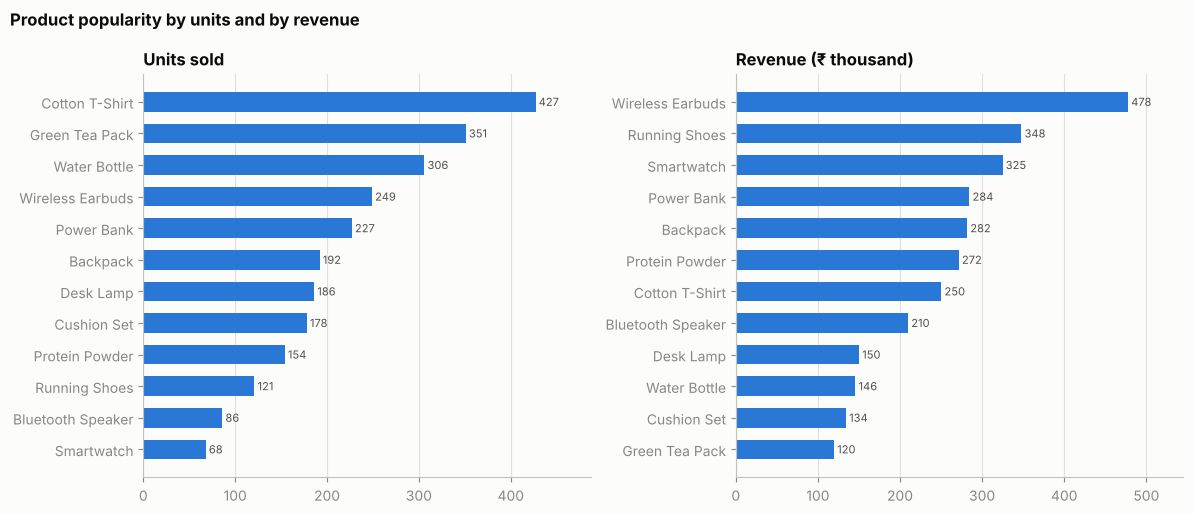

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, col, ttl in [(axes[0], "units", "Units sold"), (axes[1], "revenue", "Revenue (₹ thousand)")]:
    d = prod.sort_values(col)
    vals = d[col] if col == "units" else d[col] / 1000
    ax.barh(d["product"], vals, color=BLUE, height=0.62)
    ax.set_title(ttl); ax.grid(axis="y", visible=False); ax.margins(x=0.14)
    for y, v in enumerate(vals): ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8, color=INK2)
fig.suptitle("Product popularity by units and by revenue", x=0.01, ha="left", fontweight="bold", color=INK)
save(fig, "01_top_products")

## 4. Buying patterns: seasonality, weekdays, payments, baskets

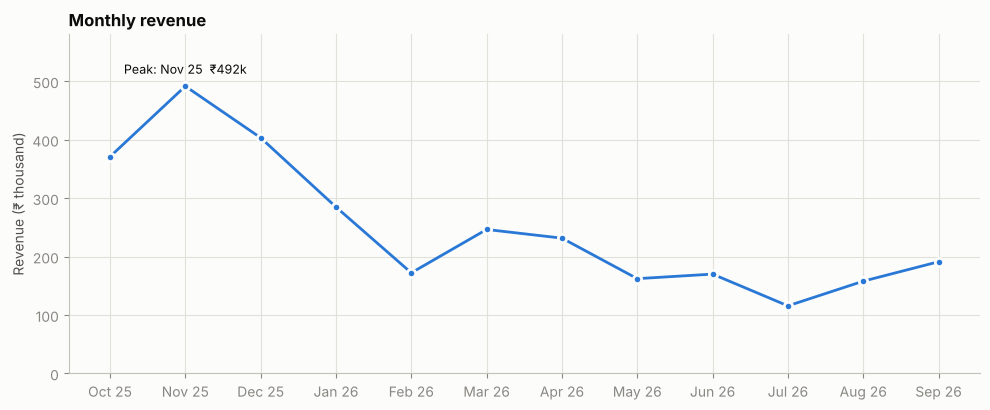

In [6]:
monthly = clean.groupby("month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
labels = [m.strftime("%b %y") for m in monthly.index]
ax.plot(labels, monthly.values / 1000, color=BLUE, lw=2, marker="o", ms=6, markeredgecolor=SURFACE, markeredgewidth=2)
pk = int(monthly.values.argmax())
ax.annotate(f"Peak: {labels[pk]}  ₹{monthly.values[pk]/1000:,.0f}k", (pk, monthly.values[pk] / 1000),
            xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, monthly.max() / 1000 * 1.18); ax.set_ylabel("Revenue (₹ thousand)"); ax.set_title("Monthly revenue")
save(fig, "02_monthly_revenue")

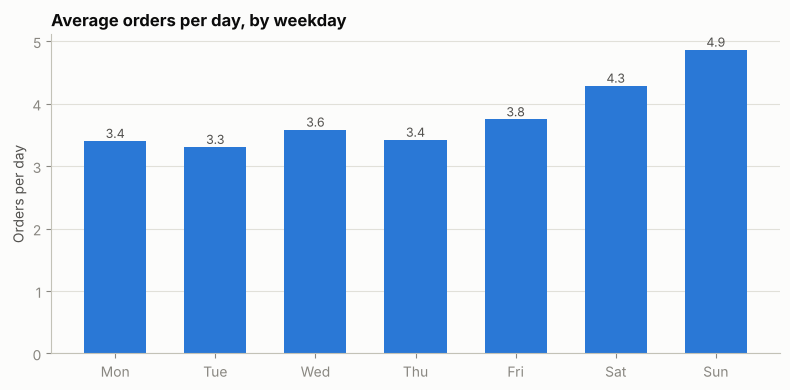

Weekend days see 1.31x the orders of weekdays


payment_method
UPI        0.489
Card       0.282
COD        0.153
Wallet     0.065
Unknown    0.010
Name: share of orders, dtype: float64

Share of orders with 2+ products: 0.228


In [7]:
orders = clean.drop_duplicates("order_id")
days = pd.date_range(clean["order_date"].min(), clean["order_date"].max())
order_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
per_day = orders.groupby("weekday").size().reindex(order_names) / days.day_name().value_counts().reindex(order_names)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([d[:3] for d in order_names], per_day.values, color=BLUE, width=0.62)
for x, v in enumerate(per_day.values): ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.grid(axis="x", visible=False); ax.set_ylabel("Orders per day"); ax.set_title("Average orders per day, by weekday")
save(fig, "03_weekday_pattern")
weekend_lift = float(per_day[["Saturday", "Sunday"]].mean() / per_day[order_names[:5]].mean())
print(f"Weekend days see {weekend_lift:.2f}x the orders of weekdays")

pay = orders["payment_method"].value_counts(normalize=True)
display(pay.round(3).rename("share of orders"))
basket = clean.groupby("order_id").agg(items=("product", "nunique"), value=("revenue", "sum"))
print("Share of orders with 2+ products:", round((basket["items"] >= 2).mean(), 3))

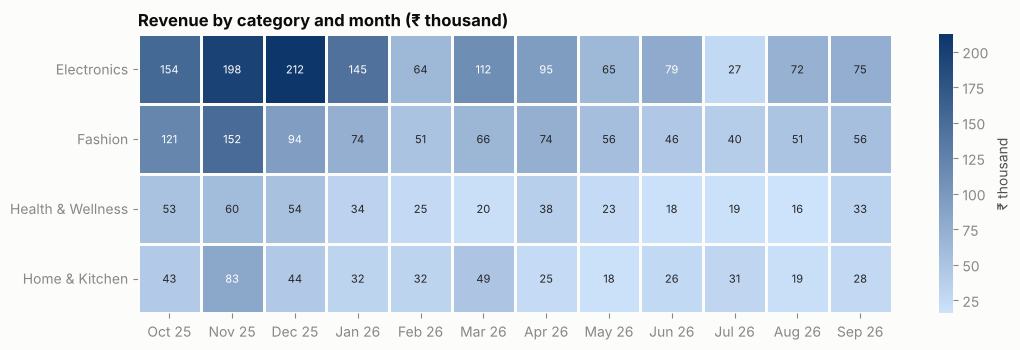

In [8]:
heat = clean.pivot_table(index="category", columns="month", values="revenue", aggfunc="sum", fill_value=0) / 1000
heat.columns = [m.strftime("%b %y") for m in heat.columns]
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#0d366b"])
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(heat, cmap=cmap, annot=True, fmt=".0f", linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "₹ thousand"}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Revenue by category and month (₹ thousand)"); ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False); plt.setp(ax.get_xticklabels(), rotation=0)
save(fig, "04_seasonality_heatmap")

,product_a,product_b,orders_together,support,lift
12,Cushion Set,Desk Lamp,31,0.022,4.436
0,Smartwatch,Wireless Earbuds,19,0.014,2.430
7,Power Bank,Wireless Earbuds,60,0.043,2.264
2,Protein Powder,Water Bottle,36,0.026,2.143
13,Cotton T-Shirt,Running Shoes,28,0.020,1.555


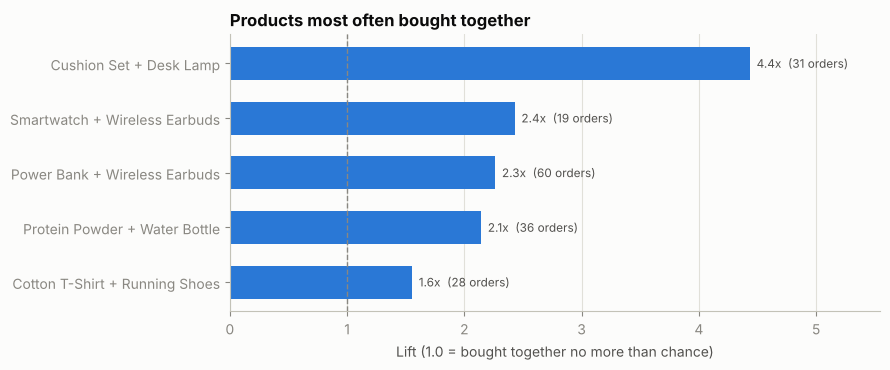

In [9]:
# Which products are bought together? (market-basket: support and lift)
baskets = clean.groupby("order_id")["product"].apply(lambda s: sorted(set(s)))
n_orders = len(baskets)
single = Counter(p for items in baskets for p in items)
pair_cnt = Counter(itertools.chain.from_iterable(itertools.combinations(items, 2) for items in baskets if len(items) > 1))
rows = []
for (a, b), c in pair_cnt.items():
    support = c / n_orders
    rows.append((a, b, c, support, support / ((single[a] / n_orders) * (single[b] / n_orders))))
pairs = pd.DataFrame(rows, columns=["product_a", "product_b", "orders_together", "support", "lift"])
top_pairs = pairs[pairs["orders_together"] >= 15].sort_values("lift", ascending=False).head(6)
display(top_pairs.round(3))

d = top_pairs.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
names = [f"{a} + {b}" for a, b in zip(d["product_a"], d["product_b"])]
ax.barh(names, d["lift"], color=BLUE, height=0.6)
for y, (l, c) in enumerate(zip(d["lift"], d["orders_together"])): ax.text(l, y, f"  {l:.1f}x  ({c} orders)", va="center", fontsize=8.5, color=INK2)
ax.axvline(1, color=MUTED, lw=1, ls="--"); ax.margins(x=0.25); ax.grid(axis="y", visible=False)
ax.set_xlabel("Lift (1.0 = bought together no more than chance)"); ax.set_title("Products most often bought together")
save(fig, "05_copurchase_pairs")

## 5. Customer segments (RFM)
Each customer is described by **Recency** (days since last order), **Frequency** (number of orders) and **Monetary** value (total spend). Fixed, readable rules turn that into segments:

| Segment | Rule |
|---|---|
| Champions | 6+ orders and ordered in the last 90 days |
| Growing Regulars | 3–5 orders and ordered in the last 90 days |
| Slipping Loyalists | 3+ orders but nothing in the last 90 days |
| New / Occasional | 1–2 orders, ordered in the last 90 days |
| Lapsed Low-Engagement | 1–2 orders and nothing in the last 90 days |

In [10]:
snapshot = clean["order_date"].max() + pd.Timedelta(days=1)
cust = (clean.groupby("customer_id")
             .agg(last_order=("order_date", "max"), frequency=("order_id", "nunique"), monetary=("revenue", "sum"))
             .reset_index())
cust["recency_days"] = (snapshot - cust["last_order"]).dt.days

def segment(r):
    recent = r["recency_days"] <= 90
    if r["frequency"] >= 6 and recent: return "Champions"
    if r["frequency"] >= 3 and not recent: return "Slipping Loyalists"
    if r["frequency"] >= 3: return "Growing Regulars"
    if recent: return "New / Occasional"
    return "Lapsed Low-Engagement"
cust["segment"] = cust.apply(segment, axis=1)

order = ["Champions", "Growing Regulars", "Slipping Loyalists", "New / Occasional", "Lapsed Low-Engagement"]
seg = (cust.groupby("segment")
           .agg(customers=("customer_id", "count"), revenue=("monetary", "sum"),
                avg_orders=("frequency", "mean"), avg_recency_days=("recency_days", "mean"))
           .reindex(order))
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg["revenue_per_customer"] = seg["revenue"] / seg["customers"]
display(seg.round(3))

top20 = cust.sort_values("monetary", ascending=False).head(int(np.ceil(0.2 * len(cust))))
top20_share = float(top20["monetary"].sum() / cust["monetary"].sum())
print(f"Top 20% of customers generate {top20_share:.1%} of revenue")
cust.drop(columns="last_order").to_csv("data/customer_segments.csv", index=False)

,customers,revenue,avg_orders,avg_recency_days,customer_share,revenue_share,revenue_per_customer
segment,,,,,,,
Champions,61,1351123.985,10.246,26.131,0.203,0.451,22149.574
Growing Regulars,39,379210.438,4.282,36.026,0.130,0.126,9723.345
Slipping Loyalists,75,915481.350,5.547,189.533,0.250,0.305,12206.418
New / Occasional,30,77870.500,1.433,33.167,0.100,0.026,2595.683
Lapsed Low-Engagement,95,274961.644,1.442,257.158,0.317,0.092,2894.333


Top 20% of customers generate 51.4% of revenue


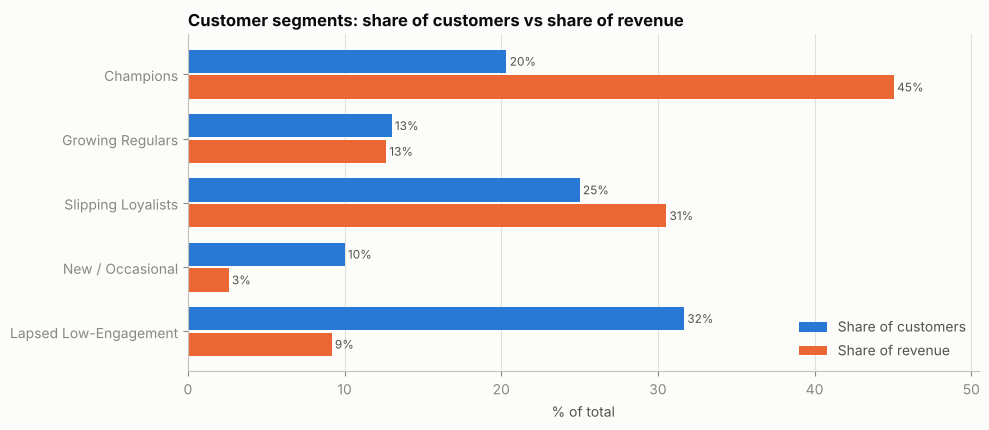

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(order)); h = 0.36
ax.barh(y - h / 2 - 0.02, seg["customer_share"] * 100, height=h, color=BLUE, label="Share of customers")
ax.barh(y + h / 2 + 0.02, seg["revenue_share"] * 100, height=h, color=ORANGE, label="Share of revenue")
for i, (a, b) in enumerate(zip(seg["customer_share"] * 100, seg["revenue_share"] * 100)):
    ax.text(a, i - h / 2 - 0.02, f" {a:.0f}%", va="center", fontsize=8.5, color=INK2)
    ax.text(b, i + h / 2 + 0.02, f" {b:.0f}%", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("% of total"); ax.set_title("Customer segments: share of customers vs share of revenue")
ax.legend(frameon=False, loc="lower right"); ax.margins(x=0.12)
save(fig, "06_customer_segments")

## 6. Save the key numbers used in the report

In [12]:
def r(x, n=4): return round(float(x), n)
top_rev = prod.sort_values("revenue", ascending=False)
top_units = prod.sort_values("units", ascending=False)
festive = clean[clean["month"].astype(str).isin(["2025-10", "2025-11", "2025-12"])]["revenue"].sum() / clean["revenue"].sum()
insights = {
    "kpi": {k: (r(v, 2) if isinstance(v, float) else v) for k, v in kpi.items()},
    "rows_raw": int(len(raw)), "rows_clean": int(len(clean)),
    "cleaning_log": [[a, b] for a, b in log],
    "top_revenue": [[p, r(v, 0), r(s)] for p, v, s in zip(top_rev["product"][:3], top_rev["revenue"][:3], top_rev["revenue_share"][:3])],
    "top_units": [[p, int(u)] for p, u in zip(top_units["product"][:3], top_units["units"][:3])],
    "bottom_revenue": [[p, r(v, 0)] for p, v in zip(top_rev["product"][-2:], top_rev["revenue"][-2:])],
    "category_share": {k: r(v) for k, v in (cat / cat.sum()).items()},
    "peak_month": labels[pk], "peak_month_revenue": r(monthly.values[pk], 0),
    "festive_share_oct_dec": r(festive),
    "avg_other_month_revenue": r(monthly.drop(monthly.index[:3]).mean(), 0),
    "weekend_lift": r(weekend_lift, 2),
    "payment_share": {k: r(v) for k, v in pay.items()},
    "multi_item_order_share": r((basket["items"] >= 2).mean()),
    "top_pairs": [[a, b, int(c), r(l, 2)] for a, b, c, l in zip(top_pairs["product_a"], top_pairs["product_b"], top_pairs["orders_together"], top_pairs["lift"])],
    "segments": [{"segment": s, "customers": int(seg.loc[s, "customers"]), "customer_share": r(seg.loc[s, "customer_share"]),
                  "revenue": r(seg.loc[s, "revenue"], 0), "revenue_share": r(seg.loc[s, "revenue_share"]),
                  "avg_orders": r(seg.loc[s, "avg_orders"], 1), "revenue_per_customer": r(seg.loc[s, "revenue_per_customer"], 0)} for s in order],
    "top20_customer_revenue_share": r(top20_share),
}
with open("data/insights.json", "w") as f: json.dump(insights, f, indent=2)
print(json.dumps(insights, indent=1)[:1500])

{
 "kpi": {
  "orders": 1388,
  "customers": 300,
  "revenue": 2998647.92,
  "aov": 2160.41,
  "items_per_order": 1.24,
  "repeat_rate": 0.77,
  "date_start": "2025-10-01",
  "date_end": "2026-09-30"
 },
 "rows_raw": 1762,
 "rows_clean": 1720,
 "cleaning_log": [
  [
   "Exact duplicate rows removed",
   30
  ],
  [
   "Blank customer_id recovered from the same order's other lines",
   8
  ],
  [
   "Blank payment_method recovered from the same order's other lines",
   11
  ],
  [
   "Rows dropped: customer_id still blank (cannot be assigned to a customer)",
   12
  ],
  [
   "Blank payment_method labelled 'Unknown'",
   14
  ],
  [
   "Dates in non-ISO formats converted to datetime",
   831
  ],
  [
   "Text prices converted to numbers",
   60
  ],
  [
   "Category text standardised (case/spaces)",
   55
  ],
  [
   "City text standardised (case/spaces, Bangalore -> Bengaluru)",
   146
  ],
  [
   "Blank quantity filled with the most common value (1)",
   15
  ],
  [
   "Negative quant